# 24 Netzereignisse und Monitorstatus für die Karte

- Der Tagesmonitor (Notebook 21) bewertet jede Station einzeln. Beginnen viele Alarme gleichzeitig, liegt die Ursache eher außerhalb des Hauses (Kälte, Vorlauf, Begehungswelle).
- Fragen: (A) Tage mit mehr Alarmstarts als zufällig? (B) Gemeinsame Alarme bei Nachbarn im Leitungsnetz? (C) Folgen für die Priorität und Status für die Karte.
- Ergebnis: `outputs/monitor_status.csv` je Station und Kernwinter, nur Zählernummern.
- Logik in `src/netzereignisse.py`, Nachbarn aus `src/nachbarschaft.py`, Stundenreihen aus Notebook 00.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import alarmbewertung as ab
from src import build_graph as bg
from src import load_begehungen as lb
from src import nachbarschaft as ns
from src import netzereignisse as ne
from src import stationsblatt as bl
from src import tagesmonitor as tm

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
T = erg["tagesmonitor"]
einsatz = ne.einsaetze(T["alarme"])
beobachtet = tm.beobachtete_tage(T["verlauf"])
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print(f"{len(einsatz)} Alarme an {einsatz['meter'].nunique()} Stationen, "
      f"{len(beobachtet)} Stationen im Monitor")
display(pd.crosstab(einsatz["kanal"], einsatz["bewertung"], margins=True))

100 Stundenreihen aus NB 00, gerechnet in 202 s
592 Alarme an 87 Stationen, 92 Stationen im Monitor


bewertung,besser,schlechter,All
kanal,,,
kwh_pro_m3,95,160,255
log_volumen,206,131,337
All,301,291,592


## A Netzereignistage

- Zeitpunkt eines Alarms ist der geschätzte Beginn der Änderung (der CUSUM braucht im Median acht Tage bis zur Schwelle).
- Je Tag: Zahl der Stationen mit Alarmbeginn im Fenster ±3 Tage. Vergleich: Alarme jeder Station 1.000-mal zufällig in ihren Überwachungstagen verschoben.
- Netzereignis: Tageswert über dem 95-%-Quantil des größten Tageswerts der Zufallsläufe (schützt gegen multiples Testen). Getrennt nach Richtung, Sensitivität mit ±1 und ±7 Tagen.

In [2]:
richtungen = {"alle": einsatz,
              "schlechter": einsatz[einsatz["bewertung"] == "schlechter"],
              "besser": einsatz[einsatz["bewertung"] == "besser"]}
netz_erg = {}
zeilen = []
for name, x in richtungen.items():
    for f in ne.FENSTER_SENSITIVITAET:
        r = ne.netztage(x, beobachtet, fenster=f, seed=0)
        netz_erg[(name, f)] = r
        zeilen.append({"richtung": name, "fenster ±Tage": f,
                       "alarme": r["n_einsaetze"], "schwelle Stationen": r["schwelle"],
                       "netztage": int(r["tage"]["netzereignis"].sum()),
                       "episoden": len(r["episoden"]),
                       "gleichzeitige Paare": r["paare_beobachtet"],
                       "zufall erwartet": r["paare_erwartet"],
                       "p global": r["p_global"]})
display(pd.DataFrame(zeilen).round(3))

,richtung,fenster ±Tage,alarme,schwelle Stationen,netztage,episoden,gleichzeitige Paare,zufall erwartet,p global
0,alle,1,564,11.0,10,6,3057.0,1961.613,0.001
1,alle,3,564,17.0,7,2,12033.0,9678.912,0.001
2,alle,7,564,26.0,0,0,40252.0,38053.915,0.021
3,schlechter,1,281,7.0,6,2,915.0,510.852,0.001
4,schlechter,3,281,11.0,9,2,3557.0,2610.216,0.001
5,schlechter,7,281,17.0,2,1,11906.0,11022.711,0.037
6,besser,1,297,7.0,7,3,1077.0,551.101,0.001
7,besser,3,297,11.0,16,4,4155.0,2867.005,0.001
8,besser,7,297,17.0,8,1,14364.0,12316.477,0.001


- In allen Varianten 6 bis 95 % mehr gleichzeitige Stationspaare als zufällig (p global höchstens 0,04).
- Über alle Alarme 564 statt 592, weil zwei Kanäle einer Station mit gleichem Starttag nur einmal zählen.
- Mit ±3 Tagen zwei Episoden für Verschlechterungen, vier für Verbesserungen. Bei ±7 Tagen liegt kaum ein Tag über der Schwelle.

- Ab hier Fenster ±3 Tage. Grafik: beginnende Verschlechterungen bzw. Verbesserungen je Tag mit Schwelle, darunter die Tagesmitteltemperatur.

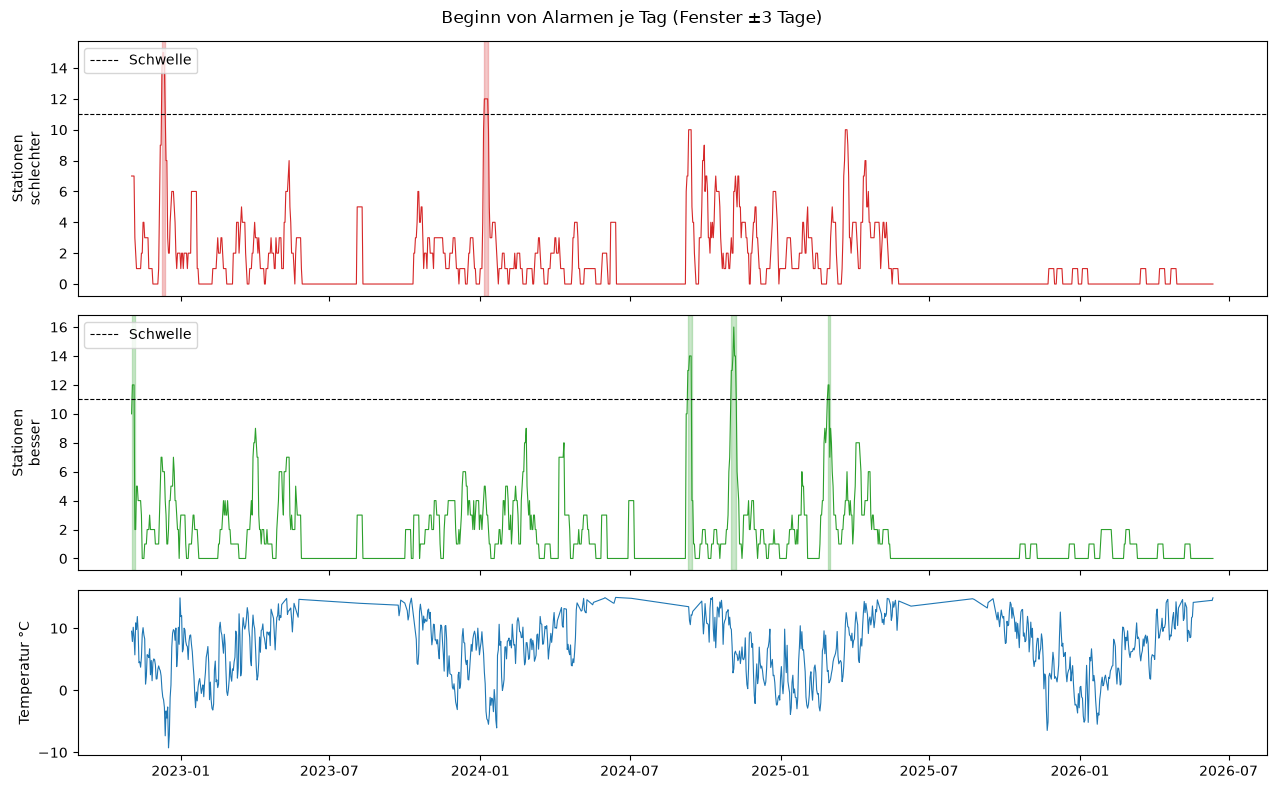

In [3]:
temp = T["verlauf"].groupby("datum")["t_mittel_c"].mean()
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True,
                       gridspec_kw={"height_ratios": [2, 2, 1.3]})
for a, name, farbe in [(ax[0], "schlechter", "tab:red"),
                       (ax[1], "besser", "tab:green")]:
    r = netz_erg[(name, ne.FENSTER_TAGE)]
    t = r["tage"]
    a.plot(t["datum"], t["n_gleichzeitig"], color=farbe, lw=0.8)
    a.axhline(r["schwelle"], color="k", ls="--", lw=0.8, label="Schwelle")
    for ep in r["episoden"].itertuples():
        a.axvspan(ep.von, ep.bis + pd.Timedelta(days=1), color=farbe, alpha=0.25)
    a.set_ylabel(f"Stationen\n{name}")
    a.legend(loc="upper left")
ax[2].plot(temp.index, temp.to_numpy(), color="tab:blue", lw=0.8)
ax[2].set_ylabel("Temperatur °C")
fig.suptitle("Beginn von Alarmen je Tag (Fenster ±3 Tage)")
fig.tight_layout()
plt.show()

- Je Episode: Temperatur davor und danach, Median-Vorlauf aller Stationen, Begehungen in ±14 Tagen.

In [4]:
vl = {}
for meter, s in e["serien"].items():
    if "vl" in s.columns:
        vl[meter] = s.loc[s["power"] > 0, "vl"].resample("D").median()
vl_netz = pd.DataFrame(vl).median(axis=1)
termine = pd.Series(sorted(pd.Timestamp(d).normalize()
                           for v in e["termine"].values() for d in v))
tag = pd.Timedelta(days=1)
tage_je_station = {m: pd.DatetimeIndex(t).normalize() for m, t in beobachtet.items()}


def neustarts(von):
    #Stationen, die in den 30 Tagen davor nicht im Monitor waren
    n = 0
    for t in tage_je_station.values():
        if ((t >= von) & (t <= von + 5 * tag)).any() \
                and not ((t < von) & (t >= von - 30 * tag)).any():
            n += 1
    return n


def kontext(ep, x):
    vor = slice(ep.von - 10 * tag, ep.von - tag)
    in_ep = slice(ep.von, ep.bis + 7 * tag)
    sub = x[(x["beginn"] >= ep.von - 3 * tag) & (x["beginn"] <= ep.bis + 3 * tag)]
    return {"von": ep.von.date(), "bis": ep.bis.date(),
            "stationen": ep.n_stationen, "im monitor": ep.n_aktiv,
            "neustart nach pause": neustarts(ep.von),
            "T davor": temp[vor].mean(), "T danach": temp[in_ep].mean(),
            "VL davor": vl_netz[vor].median(), "VL danach": vl_netz[in_ep].median(),
            "begehungen ±14 T": int(((termine >= ep.von - 14 * tag)
                                     & (termine <= ep.bis + 14 * tag)).sum()),
            "anteil volumen": (sub["kanal"] == "log_volumen").mean()}


episoden = {}
for name in ("schlechter", "besser"):
    r = netz_erg[(name, ne.FENSTER_TAGE)]
    episoden[name] = pd.DataFrame([kontext(ep, richtungen[name])
                                   for ep in r["episoden"].itertuples()])
    print(name)
    display(episoden[name].round(1))

schlechter


,von,bis,stationen,im monitor,neustart nach pause,T davor,T danach,VL davor,VL danach,begehungen ±14 T,anteil volumen
0,2022-12-09,2022-12-12,15,43,0,3.4,-3.7,73.9,74.2,0,0.5
1,2024-01-06,2024-01-10,13,48,0,7.5,-2.3,73.9,73.6,0,0.4


besser


,von,bis,stationen,im monitor,neustart nach pause,T davor,T danach,VL davor,VL danach,begehungen ±14 T,anteil volumen
0,2022-11-03,2022-11-05,12,41,2,9.5,8.3,71.9,72.0,0,1.0
1,2024-09-10,2024-09-14,14,53,53,NaN,12.0,72.9,71.3,34,0.7
2,2024-11-02,2024-11-07,18,69,0,11.1,5.6,70.1,72.4,12,0.5
3,2025-02-28,2025-03-01,12,82,0,4.2,3.2,72.3,72.8,1,0.8


- Verschlechterungswellen Dezember 2022 und Januar 2024: nach Temperatursturz um 7 bis 10 K, Vorlauf bei rund 74 °C, keine Begehungen. Passt zu einer Kennlinie, die schnelle Kälteeinbrüche nicht abfängt (Tagesmittel desselben Tages, Gebäude reagiert verzögert).
- Verbesserungswelle September 2024: Neustart aller 53 Stationen nach der Sommerpause. Passt zu den 34 Begehungen im Umfeld, das Datum ist aber ein Artefakt.
- Anfang November 2024 fallen Abkühlung, höherer Vorlauf und zwölf Begehungen zusammen, nicht trennbar. Für November 2022 und Ende Februar 2025 kein Auslöser erkennbar.

- Rangkorrelation über alle Tage: beginnende Alarme gegen Temperaturänderung (Mittel der folgenden minus der vorherigen sieben Tage). p-Wert wegen abhängiger Tage nur grob.

In [5]:
dt = (temp.rolling(7).mean().shift(-7) - temp.rolling(7).mean()).rename("dT")
zeilen = []
for name in ("schlechter", "besser"):
    t = netz_erg[(name, ne.FENSTER_TAGE)]["tage"].set_index("datum")
    d = t.join(dt, how="inner").dropna()
    d = d[d["n_aktiv"] > 0]
    rho, p = stats.spearmanr(d["n_gleichzeitig"] / d["n_aktiv"], d["dT"])
    kalt = d["dT"] <= -5
    zeilen.append({"richtung": name, "tage": len(d), "rho": rho, "p": p,
                   "anteil bei dT <= -5 K": (d.loc[kalt, "n_gleichzeitig"]
                                             / d.loc[kalt, "n_aktiv"]).mean(),
                   "anteil sonst": (d.loc[~kalt, "n_gleichzeitig"]
                                    / d.loc[~kalt, "n_aktiv"]).mean(),
                   "tage dT <= -5 K": int(kalt.sum())})
display(pd.DataFrame(zeilen).round(3))

,richtung,tage,rho,p,anteil bei dT <= -5 K,anteil sonst,tage dT <= -5 K
0,schlechter,880,0.087,0.01,0.092,0.045,54
1,besser,880,-0.164,0.00,0.072,0.061,54


- An den 54 Tagen mit mindestens 5 K Abkühlung binnen einer Woche beginnen doppelt so oft Verschlechterungen (9,2 % gegen 4,5 % der überwachten Stationen).
- Über alle Tage schwach (rho 0,09). Verbesserungen bei Abkühlung ebenfalls etwas häufiger.

## B Gleichzeitige Alarme bei Nachbarn

- Nachbarn wie in Notebook 23 über den logischen Leitungsgraphen, bis eine, zwei oder drei Kanten.
- Gleichzeitig: Alarme derselben Richtung mit höchstens drei Tagen Abstand im Beginn.
- Vergleich: Stationen 10.000-mal zufällig auf die Knoten verteilt. Gemessen wird nur der Effekt der Netznähe über netzweite Ereignisse hinaus.

In [6]:
graph = bg.build_logical_graph()
im_graph = set(ns.meter_knoten(graph)) & set(beobachtet)
nachbarn = {k: ns.nachbarn(graph, k) for k in ns.KANTEN_SENSITIVITAET}
print(f"{len(im_graph)} Stationen im Monitor und im Graph")
zeilen = []
for k, nb in nachbarn.items():
    pr = ns.paare(nb)
    for name, x in richtungen.items():
        r = ne.nachbar_gleichzeitig(x, pr, fenster=ne.FENSTER_TAGE,
                                    stationen=im_graph, seed=0)
        zeilen.append({"kanten": k, "richtung": name, "paare": r["paare"],
                       "gleichzeitig": r["beobachtet"],
                       "zufall erwartet": r["erwartet"], "p": r["p"]})
nachbar_tab = pd.DataFrame(zeilen)
display(nachbar_tab.round(3))

78 Stationen im Monitor und im Graph


,kanten,richtung,paare,gleichzeitig,zufall erwartet,p
0,1,alle,49,15,13.671,0.380
1,1,schlechter,49,6,4.840,0.355
2,1,besser,49,7,5.237,0.259
3,2,alle,111,35,30.999,0.218
4,2,schlechter,111,12,10.929,0.405
5,2,besser,111,17,11.903,0.081
6,3,alle,173,60,48.298,0.032
7,3,schlechter,173,21,17.017,0.182
8,3,besser,173,24,18.532,0.111


- Gleichzeitige Nachbarpaare bei zwei Kanten, nur mit Zählernummern.

In [7]:
paare2 = ns.paare(nachbarn[ns.MAX_KANTEN])
treffer = []
for name in ("schlechter", "besser"):
    r = ne.nachbar_gleichzeitig(richtungen[name], paare2, fenster=ne.FENSTER_TAGE,
                                stationen=im_graph, n=1, seed=0)
    treffer.append(r["treffer"].assign(richtung=name))
treffer = pd.concat(treffer, ignore_index=True)
display(treffer.sort_values(["richtung", "beginn_a"]))

,meter_a,meter_b,beginn_a,beginn_b,abstand_tage,richtung
12,65273846,72135481,2022-11-02,2022-11-02,0,besser
20,68956367,72135463,2022-11-02,2022-11-02,0,besser
15,68956347,72135490,2023-05-01,2023-05-04,3,besser
16,68956348,68956367,2023-12-27,2023-12-30,3,besser
13,68956344,68956348,2023-12-29,2023-12-27,2,besser
21,68956371,72135453,2024-02-29,2024-02-27,2,besser
18,68956355,69513891,2024-07-03,2024-07-03,0,besser
17,68956353,80912195,2024-09-11,2024-09-11,0,besser
26,80912162,80912180,2024-09-11,2024-09-11,0,besser
27,80912162,80912197,2024-09-11,2024-09-11,0,besser


- Nachbarn alarmieren nicht häufiger gemeinsam als zufällige Paare. Nur einer von neun Tests unter 0,05 (drei Kanten, alle Alarme, p 0,03), bei neun Tests erwartbar.
- Die meisten gleichzeitigen Paare liegen auf den Netzereignistagen aus Teil A. Kein Hinweis auf Probleme einzelner Stränge, wie in Notebook 23.

## C Markierung je Alarm und Wirkung auf die Priorität

- `netzereignis`: Beginn höchstens drei Tage neben einem Netzereignistag derselben Richtung.
- `nachbar_gleichzeitig`: Nachbar (bis zwei Kanten) mit Alarm derselben Richtung, Beginn höchstens drei Tage daneben.
- Priorität aus Notebook 22 bleibt. Sensitivität: Priorität ohne Verschlechterungen an Netzereignistagen.

In [8]:
markiert = []
for name in ("schlechter", "besser"):
    t = netz_erg[(name, ne.FENSTER_TAGE)]["tage"]
    markiert.append(ne.markiere(richtungen[name],
                                t.loc[t["netzereignis"], "datum"], paare2,
                                fenster=ne.FENSTER_TAGE))
markiert = pd.concat(markiert, ignore_index=True)
display(pd.crosstab(markiert["bewertung"],
                    [markiert["netzereignis"], markiert["nachbar_gleichzeitig"]],
                    margins=True))

prio = erg["prioritaet"]
ohne_netz = markiert[~(markiert["netzereignis"]
                       & (markiert["bewertung"] == "schlechter"))]
alle_alarme = T["alarme"].assign(
    meter=T["alarme"]["meter"].astype(int),
    datum=pd.to_datetime(T["alarme"]["datum"]).dt.normalize())
alarme_ohne = alle_alarme.merge(ohne_netz[["meter", "kanal", "datum"]],
                                on=["meter", "kanal", "datum"])
assert len(alarme_ohne) == len(ohne_netz)
prio_ohne = ab.prioritaet_je_winter(erg["markiert"], alarme_ohne)
vergleich = prio.merge(prio_ohne[["meter", "winter", "prioritaet"]],
                       on=["meter", "winter"], suffixes=("", "_ohne_netz"))
display(pd.crosstab(vergleich["prioritaet"], vergleich["prioritaet_ohne_netz"],
                    margins=True))

netzereignis         False       True       All
nachbar_gleichzeitig False True False True     
bewertung                                      
besser                 227   11    41   22  301
schlechter             240   18    23   10  291
All                    467   29    64   32  592

prioritaet_ohne_netz,hoch,mittel,niedrig,All
prioritaet,,,,
hoch,16,0,0,16
mittel,0,91,10,101
niedrig,0,0,94,94
All,16,91,104,211


In [9]:
geaendert = vergleich[vergleich["prioritaet"] != vergleich["prioritaet_ohne_netz"]]
display(geaendert[["meter", "winter", "auffaellig", "alarme_schlechter",
                   "prioritaet", "prioritaet_ohne_netz"]]
        .sort_values(["winter", "meter"]))

,meter,winter,auffaellig,alarme_schlechter,prioritaet,prioritaet_ohne_netz
1,53198226,22/23,False,1,mittel,niedrig
4,61620222,22/23,False,1,mittel,niedrig
15,68956355,22/23,False,1,mittel,niedrig
26,69527340,22/23,False,1,mittel,niedrig
28,69631918,22/23,False,1,mittel,niedrig
58,68956359,23/24,False,2,mittel,niedrig
62,68956366,23/24,False,1,mittel,niedrig
70,69527345,23/24,False,1,mittel,niedrig
71,69631918,23/24,False,1,mittel,niedrig
72,72135440,23/24,False,1,mittel,niedrig


- 96 der 592 Alarme beginnen an einem Netzereignistag (33 Verschlechterungen), 61 haben einen gleichzeitigen Nachbarn.
- Alle 16 Stationswinter mit hoher Priorität bleiben hoch. Zehn fallen von mittel auf niedrig, alle im Netzvergleich unauffällig mit einzigem Verschlechterungsalarm in einer Netzwelle.
- Nutzen vor allem im Betrieb: neuen Alarm einordnen, bevor jemand hinfährt.

## D Monitorstatus für die Karte

- `outputs/monitor_status.csv`: je Station und Kernwinter Priorität, Netzwert, Rang, Fehlerbild, chronisch und Alarmzahlen. Keine Adressen.
- Dazu `outputs/monitor_alarme.csv` und `outputs/netzereignistage.csv`. Notebook 25 legt alle drei auf eine Kopie der Karte aus Netz-Notebook 16.

In [10]:
fb = ab.fehlerbild_je_winter(erg["markiert"], list(erg["kennzahlen"]))
status = ne.monitor_status(prio, erg["markiert"], fb, erg["uebersicht"], markiert)
ziel = ROOT / "outputs" / "monitor_status.csv"
ziel.parent.mkdir(parents=True, exist_ok=True)
status.to_csv(ziel, index=False)
print(f"{len(status)} Zeilen, {status['meter'].nunique()} Stationen -> "
      f"{ziel.relative_to(ROOT)}")
#Alarme und Ereignistage für die Zeitachse der Karte
markiert.sort_values(["meter", "datum"]).to_csv(
    ziel.parent / "monitor_alarme.csv", index=False, date_format="%Y-%m-%d")
pd.concat([netz_erg[(name, ne.FENSTER_TAGE)]["episoden"]
           [["von", "bis", "n_stationen", "n_aktiv"]].assign(richtung=name)
           for name in ("schlechter", "besser")]).to_csv(
    ziel.parent / "netzereignistage.csv", index=False, date_format="%Y-%m-%d")
print(f"{len(markiert)} Alarme -> outputs/monitor_alarme.csv, Episoden -> "
      "outputs/netzereignistage.csv")
display(pd.crosstab(status["winter"], status["prioritaet"], margins=True))
display(status[status["prioritaet"] == "hoch"].sort_values(["winter", "rang"]).head(15))

211 Zeilen, 93 Stationen -> outputs\monitor_status.csv
592 Alarme -> outputs/monitor_alarme.csv, Episoden -> outputs/netzereignistage.csv


prioritaet,hoch,mittel,niedrig,All
winter,,,,
22/23,5,24,12,41
23/24,2,33,50,85
24/25,9,44,32,85
All,16,101,94,211


,meter,winter,prioritaet,auffaellig,score,rang,fehlerbild,chronisch,alarme_schlechter,alarme_besser,alarme_netzereignis,alarme_nachbar
12,68956351,22/23,hoch,True,2.506965,1.0,ventil,True,1,1,0,0
39,72167783,22/23,hoch,True,1.836333,2.0,unruhig,False,2,5,0,0
30,72135442,22/23,hoch,True,1.821632,3.0,ventil,True,1,1,0,0
31,72135453,22/23,hoch,True,1.328008,5.0,durchfluss,True,2,1,0,0
7,68956339,22/23,hoch,True,1.021389,6.0,unruhig,False,3,2,0,0
66,68956372,23/24,hoch,True,2.417011,4.0,ventil,False,1,0,0,0
76,72135453,23/24,hoch,True,1.932533,7.0,durchfluss,True,2,3,0,1
191,80912182,24/25,hoch,True,2.045287,1.0,ventil,True,2,1,1,1
155,72135442,24/25,hoch,True,1.935079,3.0,unruhig,True,2,2,0,0
170,72167793,24/25,hoch,True,1.871512,4.0,ventil,True,2,0,0,0


## E Nachbarn über die Luftlinie

- Koordinaten aus der Handliste `adressen_koordinaten.ods` von Notebook 16 (nicht im Repository, lokal unter `data/manual/`). Die Nominatim-Positionen in `data/processed/hast_geocoded.csv` sind meist nur straßengenau.
- Test wie in Notebook 23 mit Nachbarn im Umkreis von 50, 100 und 200 m.

In [11]:
liste = ROOT / "data" / "manual" / "adressen_koordinaten.ods"
if not liste.exists():
    print("Übersprungen: data/manual/adressen_koordinaten.ods fehlt.")
else:
    pos = ns.positionen_aus_handliste(liste, lb.meter_to_address())
    netz = erg["markiert"]
    mit_pos = set(pos["meter"])
    print(f"{len(mit_pos)} Zähler mit Koordinate")
    zeilen = []
    for radius in ns.RADIUS_SENSITIVITAET:
        pr = ns.paare(ns.radius_nachbarn(pos, radius))
        for w, t in netz[netz["score"].notna()].groupby("winter"):
            j = ns.join_test(pr, dict(zip(t["meter"], t["auffaellig"])),
                             stationen=mit_pos)
            s = ns.score_test(pr, dict(zip(t["meter"], t["score"])),
                              stationen=mit_pos)
            zeilen.append({"radius m": radius, "winter": w, "paare": j["paare"],
                           "beide auffaellig": j["beobachtet"],
                           "zufall erwartet": j["erwartet"], "p Paare": j["p"],
                           "rho Score": s["beobachtet"], "p Score": s["p"]})
        g = ne.nachbar_gleichzeitig(richtungen["schlechter"], pr,
                                    stationen=mit_pos & set(beobachtet), seed=0)
        zeilen.append({"radius m": radius, "winter": "Alarme schlechter",
                       "paare": g["paare"], "beide auffaellig": g["beobachtet"],
                       "zufall erwartet": g["erwartet"], "p Paare": g["p"]})
    display(pd.DataFrame(zeilen).round(3))

102 Zähler mit Koordinate


,radius m,winter,paare,beide auffaellig,zufall erwartet,p Paare,rho Score,p Score
0,50,22/23,43,0,1.019,1.000,0.367,0.005
1,50,23/24,149,3,1.656,0.218,0.120,0.049
2,50,24/25,162,3,3.123,0.601,0.144,0.026
3,50,Alarme schlechter,154,16,13.643,0.282,NaN,NaN
4,100,22/23,182,3,4.347,0.825,-0.012,0.301
5,100,23/24,519,8,5.822,0.211,-0.037,0.710
6,100,24/25,537,9,10.377,0.686,0.003,0.288
7,100,Alarme schlechter,532,58,47.077,0.062,NaN,NaN
8,200,22/23,434,12,10.338,0.316,0.058,0.004
9,200,23/24,1366,19,15.218,0.198,0.009,0.106


- Gemeinsam auffällig werden Nachbarn in keinem Radius und Winter häufiger als zufällig (p zwischen 0,2 und 1,0).
- Scores sehr naher Häuser hängen leicht zusammen: bei 50 m in allen drei Wintern (rho 0,37, 0,12 und 0,14 bei p 0,005, 0,049 und 0,026). Bei 100 m verschwindet das.
- Gleichzeitige Verschlechterungen bei 200 m etwas häufiger (148 statt 125 Paare, p 0,018).
- Bei zwölf Tests sind einzelne kleine p-Werte Zufall. Der 50-m-Effekt passt eher zu ähnlichen Gebäuden als zu einem Netzfehler.

## Zusammenfassung & Bewertung

- Alarme häufen sich an einzelnen Tagen netzweit. Die Verschlechterungswellen fallen auf Kälteeinbrüche bei unverändertem Vorlauf, ein Hinweis auf eine Schwäche der Kennlinie, nicht auf Hausfehler. Die Verbesserungswelle im September 2024 ist ein Neustart-Artefakt.
- Belastbar: Kein gemeinsames Muster von Nachbarn über die Netzereignisse hinaus, Auffälligkeiten passen zu Ursachen an der einzelnen Station.
- Praxis: Jeder Alarm trägt `netzereignis` und `nachbar_gleichzeitig`. Alarme an Netzereignistagen erst gegen Wetter und Netz prüfen. Die Spitze der Prioritätsliste bleibt gleich.
- Schwach: Graph ohne Längen und Drücke, strenge Schwelle (Wellen mit fünf oder sechs Stationen fallen darunter), Alarmbeginn nur geschätzt.
- Offen: Kennlinie mit geglätteter oder um einen Tag verzögerter Temperatur rechnen und prüfen, ob die Wellen kleiner werden.